# 02 · Distance and usage (Phase 3, step 1)

**Goal.** Layer 1 forecasts ("oil due in ~1,200 km, around 18 Dec") need three numbers we
mustn't guess:
1. **How to measure distance** from 1 Hz speed, and what to do when samples are missing.
2. **How to forecast km per day**, so km can be turned into a date.
3. **When an odometer typed in by the owner disagrees** with our estimate enough to flag it.

**Data**
| Source | Used for |
|---|---|
| VED (264 petrol cars, Michigan, 2017–18; speed ~1.5 Hz, GPS fix every ~5 s) | speed vs GPS distance, gaps, sensor bias between cars, daily-km series |
| Simulator (Phase 2, Lagos schedule; true distance known) | the same checks where the truth is exact, and a Lagos km/day series |

**Outputs**
- `ml/reports/phase3_distance.md`: findings with evidence.
- `ml/reports/phase3_distance.yaml`: the numbers the backend uses (all `SEED - validate`).

**Rules:** split by **vehicle**, never by random rows of the same car; every method is
compared with a **trivial baseline**; summaries are medians and percentiles.

In [1]:
import math, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from dotenv import load_dotenv

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve().parent
load_dotenv(REPO / ".env")
DATASETS_DIR = Path(os.environ["DATASETS_DIR"])
RAW, INTERIM = DATASETS_DIR / "raw", DATASETS_DIR / "interim"
REBUILD_CACHE = os.environ.get("REBUILD_CACHE", "0") == "1"
sys.path.insert(0, str(REPO / "simulator"))
pd.set_option("display.width", 140, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7, 3.2)})
RNG = np.random.default_rng(2026)
OUT = {}  # everything that goes into phase3_distance.yaml

def pct(s, ps=(10, 50, 90), nd=3):
    s = pd.Series(s).dropna()
    return {f"p{p}": round(float(np.percentile(s, p)), nd) for p in ps} | {"n": int(len(s))}

R_EARTH = 6_371_008.8
def haversine_m(lat1, lon1, lat2, lon2):
    # Great-circle distance between two points on a sphere the size of the Earth.
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))

def trapz_km(t_s, v_kmh, max_step_s=np.inf):
    # Area under speed-vs-time: each slice adds the mean of its two speeds × its duration.
    # Steps longer than max_step_s are holes: left out here, handled by the gap policy.
    dt = np.diff(t_s)
    seg = (v_kmh[1:] + v_kmh[:-1]) / 2 / 3600 * dt
    return float(seg[dt <= max_step_s].sum())

## 1. Speed integral vs GPS distance on VED

Per trip: the trapezoidal speed integral (steps over 10 s left out) and the GPS distance.
GPS details that matter:
- VED repeats the last fix between updates (~5 s), so only rows where the position
  **changed** are fixes.
- A parked car's GPS wanders a few metres. Summed over a trip that's ~40 m of distance
  that never happened, so a hop counts only if the car was moving (speed > 1 km/h) at
  either end of it.

In [2]:
COLS = {"VehId": "veh", "Trip": "trip", "DayNum": "day", "Timestamp(ms)": "t_ms",
        "Latitude[deg]": "lat", "Longitude[deg]": "lon", "Vehicle Speed[km/h]": "v"}
st = pd.read_excel(RAW / "ved/static/VED_Static_Data_ICE&HEV.xlsx")
petrol = set(st.loc[st["Vehicle Type"] == "ICE", "VehId"])

def trip_distance(d: pd.DataFrame) -> dict:
    t = d.t_ms.to_numpy() / 1000
    v = d.v.to_numpy()
    fix = np.r_[True, (np.diff(d.lat.to_numpy()) != 0) | (np.diff(d.lon.to_numpy()) != 0)]
    fx = d[fix]
    hop = haversine_m(fx.lat.to_numpy()[:-1], fx.lon.to_numpy()[:-1],
                      fx.lat.to_numpy()[1:], fx.lon.to_numpy()[1:])
    moving = (fx.v.to_numpy()[:-1] > 1) | (fx.v.to_numpy()[1:] > 1)
    return {"dur_s": t[-1] - t[0], "n": len(d), "n_fix": int(fix.sum()),
            "dist_speed_km": trapz_km(t, v, 10.0),
            "dist_gps_km": float(hop[moving].sum()) / 1000,
            "gps_raw_km": float(hop.sum()) / 1000,
            "max_step_s": float(np.diff(t).max()) if len(t) > 1 else 0.0}

cache = INTERIM / "ved_distance.parquet"
if cache.exists() and not REBUILD_CACHE:
    vd = pd.read_parquet(cache)
    print(f"loaded cache {cache.name}: {len(vd)} trips")
else:
    t0, rows = time.time(), []
    for f in sorted((RAW / "ved/dynamic").glob("*/*.csv")):
        df = pd.read_csv(f, usecols=list(COLS)).rename(columns=COLS)
        df = df[df.veh.isin(petrol)].dropna(subset=["v", "lat", "lon"])
        for (veh, trip), d in df.sort_values(["veh", "trip", "t_ms"]).groupby(["veh", "trip"]):
            if len(d) >= 30:
                rows.append({"veh": veh, "trip": trip, "day": d.day.min(), **trip_distance(d)})
    vd = pd.DataFrame(rows)
    INTERIM.mkdir(exist_ok=True)
    vd.to_parquet(cache, index=False)
    print(f"processed in {time.time() - t0:.0f} s -> {len(vd)} trips")
vd["ratio"] = vd.dist_gps_km / vd.dist_speed_km
# "Clean" trips for comparisons: long enough, GPS fixes all along (no tunnel/garage holes).
fix_every_s = vd.dur_s / vd.n_fix.clip(lower=1)
clean = vd[(vd.dist_speed_km >= 1) & (fix_every_s < 8) & (vd.max_step_s <= 10)]
print(f"{len(clean)} clean trips of {len(vd)}; {clean.veh.nunique()} cars")
print("GPS / speed distance, clean trips:", pct(clean.ratio))
print("parked-GPS jitter removed per trip (km):", pct(vd.gps_raw_km - vd.dist_gps_km))
OUT["ved_gps_over_speed"] = pct(clean.ratio)

loaded cache ved_distance.parquet: 18930 trips
17068 clean trips of 18930; 261 cars
GPS / speed distance, clean trips: {'p10': 0.984, 'p50': 1.007, 'p90': 1.036, 'n': 17068}
parked-GPS jitter removed per trip (km): {'p10': 0.0, 'p50': 0.007, 'p90': 0.059, 'n': 18930}


207 cars with >= 10 clean trips; speed-sensor bias vs GPS (%): {'p5': -1.579, 'p50': 0.675, 'p95': 3.293, 'n': 207}


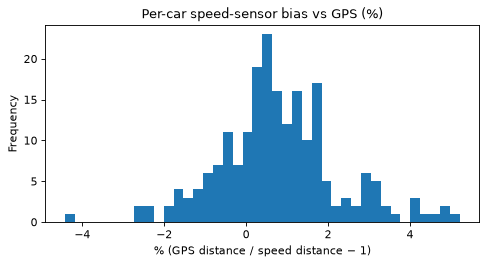

In [3]:
# Per-car bias: each car's speed sensor reads a little high or low (tyre size and wear,
# calibration). A car's median GPS/speed ratio over its trips estimates its bias.
per_car = clean.groupby("veh").ratio.agg(["median", "size"])
per_car = per_car[per_car["size"] >= 10]
bias = (per_car["median"] - 1) * 100
print(f"{len(per_car)} cars with >= 10 clean trips; speed-sensor bias vs GPS (%):", pct(bias, (5, 50, 95)))
OUT["ved_per_car_bias_pct"] = pct(bias, (5, 50, 95))
ax = bias.clip(-10, 10).plot.hist(bins=40, title="Per-car speed-sensor bias vs GPS (%)")
ax.set_xlabel("% (GPS distance / speed distance − 1)");

## 2. Sampling rate

Our device polls speed at 1 Hz (P5). How much distance does a slower poll lose? Each clean
trip is resampled to 1 Hz (the reference), then to one sample every 2, 5 and 10 s.

In [4]:
def load_1hz(veh_trips: pd.DataFrame, max_trips=400) -> dict:
    # Re-read the raw rows of a sample of clean trips, resampled to a 1 Hz grid.
    want = veh_trips.sample(min(max_trips, len(veh_trips)), random_state=1)
    keys = set((want.veh.astype(np.int64) * 1_000_000 + want.trip.astype(np.int64)).tolist())
    out = {}
    for f in sorted((RAW / "ved/dynamic").glob("*/*.csv")):
        df = pd.read_csv(f, usecols=list(COLS)).rename(columns=COLS)
        kk = df.veh.astype(np.int64) * 1_000_000 + df.trip.astype(np.int64)
        df = df[kk.isin(keys)].dropna(subset=["v", "lat", "lon"])
        for k, d in df.sort_values("t_ms").groupby(["veh", "trip"]):
            t = d.t_ms.to_numpy() / 1000
            grid = np.arange(0, t[-1], 1.0)
            fix = np.r_[True, (np.diff(d.lat.to_numpy()) != 0) | (np.diff(d.lon.to_numpy()) != 0)]
            out[k] = {"t": grid, "v": np.interp(grid, t, d.v.to_numpy()),
                      "fix_t": t[fix], "lat": d.lat.to_numpy()[fix], "lon": d.lon.to_numpy()[fix]}
    return out

cache1 = INTERIM / "ved_trips_1hz.pkl"
long_clean = clean[clean.dur_s >= 600]
if cache1.exists() and not REBUILD_CACHE:
    hz = pd.read_pickle(cache1)
else:
    t0 = time.time()
    hz = load_1hz(long_clean)
    pd.to_pickle(hz, cache1)
    print(f"resampled {len(hz)} trips in {time.time() - t0:.0f} s")
print(f"{len(hz)} long clean trips at 1 Hz, {len({k[0] for k in hz})} cars")

rows = []
for k, tr in hz.items():
    ref = trapz_km(tr["t"], tr["v"])
    for every in (2, 5, 10):
        rows.append({"every_s": every, "err_pct": (trapz_km(tr["t"][::every], tr["v"][::every]) / ref - 1) * 100})
samp = pd.DataFrame(rows)
tbl = samp.groupby("every_s").err_pct.apply(lambda s: pct(s.abs(), (50, 90, 99))).unstack()
print("distance error vs 1 Hz (|%|):"); print(tbl)
OUT["sampling_error_abs_pct"] = {int(k): v for k, v in tbl.to_dict("index").items()}

400 long clean trips at 1 Hz, 141 cars
distance error vs 1 Hz (|%|):
           p50    p90    p99      n
every_s                            
2        0.084  0.251  0.398  400.0
5        0.241  0.743  1.533  400.0
10       0.617  1.718  3.640  400.0


## 3. Gaps: bridge, GPS, or report

Our gaps are of two kinds:
- **Short** (a few seconds): single PID reads that timed out (P5: 0.4 % of reads).
- **Long:** in a v1 device, batches aren't lost (store-and-forward), so a long hole means
  the device lost power, its flash overflowed, or a batch is still on its way (the trip
  is re-summarised when it arrives).

For holes of 2 s to 10 min, cut at random moving points of the long clean trips:
- **bridge:** a straight line between the speeds either side of the hole, `(v_before + v_after) / 2 × L`.
- **chord:** the GPS straight-line distance between the last fix before and the first fix
  after. Roads bend, so this undercounts; **chord × detour** corrects it with the median
  route/chord ratio for that hole length, **learned on half the cars and tested on the
  other half**.
- **Trivial baseline:** the trip's average speed × L.

The error is measured against the true distance in the hole (the 1 Hz integral).

In [5]:
cars = sorted({k[0] for k in hz})
train_cars = set(RNG.choice(cars, len(cars) // 2, replace=False))
LENS = [2, 5, 10, 20, 30, 60, 120, 300, 600]

def cut(tr, L):
    # A hole of L seconds starting at a random moving point, not at the trip's very ends.
    n = len(tr["t"])
    starts = np.flatnonzero(tr["v"][: n - L - 1] > 5)
    starts = starts[(starts > 5)]
    if len(starts) == 0:
        return None
    i = int(RNG.choice(starts)); j = i + L
    truth = trapz_km(tr["t"][i:j + 1], tr["v"][i:j + 1])
    before = np.flatnonzero(tr["fix_t"] <= tr["t"][i]); after = np.flatnonzero(tr["fix_t"] >= tr["t"][j])
    if len(before) == 0 or len(after) == 0:
        return None
    b, a = before[-1], after[0]
    chord = haversine_m(tr["lat"][b], tr["lon"][b], tr["lat"][a], tr["lon"][a]) / 1000
    span = tr["fix_t"][a] - tr["fix_t"][b]
    # The fixes bracket a little more than the hole; scale the chord to the hole's length.
    chord_hole = chord * L / span if span > 0 else 0.0
    return {"L": L, "truth": truth, "bridge": (tr["v"][i] + tr["v"][j]) / 2 / 3600 * L,
            "chord": chord_hole, "mean_speed": tr["v"].mean() / 3600 * L}

rows = []
for k, tr in hz.items():
    for L in LENS:
        for _ in range(3):
            r = cut(tr, L)
            if r and r["truth"] > 0.005:
                rows.append({"veh": k[0], **r})
gaps = pd.DataFrame(rows)
gaps["train"] = gaps.veh.isin(train_cars)
detour = (gaps[gaps.train & (gaps.chord > 0)].assign(r=lambda d: d.truth / d.chord)
          .groupby("L").r.median())
print("detour factor (route / chord), learned on training cars:"); print(detour.round(3).to_dict())
test = gaps[~gaps.train].copy()
test["chord_x_detour"] = test.chord * test.L.map(detour)
methods = ["bridge", "chord", "chord_x_detour", "mean_speed"]
err = pd.DataFrame({m: (test[m] - test.truth).abs() / test.truth * 100 for m in methods})
err["L"] = test.L
tbl = err.groupby("L").median().round(1)
print("\nmedian |error| as % of the hole's true distance (test cars):"); print(tbl)
OUT["gap_detour_factor"] = {int(k): round(float(v), 3) for k, v in detour.items()}
OUT["gap_median_abs_err_pct"] = {int(L): r for L, r in tbl.to_dict("index").items()}

detour factor (route / chord), learned on training cars:
{2: 0.997, 5: 1.0, 10: 1.005, 20: 1.007, 30: 1.017, 60: 1.035, 120: 1.077, 300: 1.147, 600: 1.251}

median |error| as % of the hole's true distance (test cars):
     bridge  chord  chord_x_detour  mean_speed
L                                             
2       0.4    3.8             3.8        38.4
5       1.2    3.6             3.6        39.6
10      3.3    4.0             4.1        39.1
20      8.1    3.7             3.8        38.0
30     14.0    4.4             4.5        37.6
60     21.0    5.2             6.0        35.8
120    29.4    8.8             8.7        29.4
300    34.5   12.6            11.0        21.5
600    42.7   19.3            11.1         6.6


In [6]:
# Policy: bridge while bridging is within 10 % (median) of the truth; beyond that, use the
# GPS chord × detour if fixes exist, otherwise bridge but mark the trip's distance partial.
BRIDGE_TOL_PCT = 10.0
ok = tbl.index[tbl["bridge"] <= BRIDGE_TOL_PCT]
bridge_max_s = int(max(ok)) if len(ok) else 2
better_gps = tbl.index[tbl["chord_x_detour"] < tbl["bridge"]]
print(f"bridge holes up to {bridge_max_s} s (median error <= {BRIDGE_TOL_PCT} %)")
print(f"GPS chord x detour beats bridging from {int(min(better_gps)) if len(better_gps) else 'never'} s")
OUT["bridge_max_s"] = bridge_max_s
OUT["gps_better_from_s"] = int(min(better_gps)) if len(better_gps) else None

# Trip-level flag: when do speed and GPS disagree enough to say "check this trip"?
flag = float(np.percentile((clean.ratio - 1).abs(), 99)) * 100
print(f"|GPS/speed − 1| at the 99th percentile of clean trips: {flag:.1f} %")
OUT["gnss_disagree_flag_pct"] = round(math.ceil(flag), 0)

bridge holes up to 20 s (median error <= 10.0 %)
GPS chord x detour beats bridging from 20 s
|GPS/speed − 1| at the 99th percentile of clean trips: 12.2 %


## 4. The same on simulated Lagos trips (true distance known)

The simulator knows each trip's true distance. The emulated device polls speed at 1 Hz
with read latency, integer rounding and the occasional failed read (Phase 2, step 5). We
integrate exactly what the device sends, then remove one whole 60 s batch from some
trips to exercise the gap policy.

In [7]:
from autocare_sim.device import Device
from autocare_sim.run import simulate

def device_speed(run_, trip_no):
    pts = []
    for b in run_.produced:
        if b["trip"] == trip_no:
            pts += [(b["t0"] + dt, v) for dt, v in b["s"].get("speed", [])]
    pts.sort()
    return np.array([p[0] for p in pts]) / 1000, np.array([p[1] for p in pts], float)

rows = []
for k, pid in enumerate(["toyota_corolla_1_8_2009", "lexus_rx350_3_5_2010", "toyota_sienna_3_5_2011"]):
    tl = simulate(pid, days=10, seed=40 + k)
    run_ = Device(f"FM1-{k:04d}", tl, seed=40 + k, clock_faults=False).run(drain_days=0)
    for n, tr in enumerate(tl.trips, start=1):
        t, v = device_speed(run_, n)
        if len(t) < 120:
            continue
        true_km = tr.out.distance_km
        full = trapz_km(t, v, bridge_max_s)
        # Lose one 60 s stretch in the middle (a batch that never arrived).
        mid = len(t) // 2
        keep = np.r_[np.arange(mid), np.arange(mid + 60, len(t))]
        tk, vk = t[keep], v[keep]
        holes = np.diff(tk) > bridge_max_s
        bridged = trapz_km(tk, vk)  # bridge everything (what a naive integral does)
        rows.append({"car": pid, "true_km": true_km, "full_err_pct": (full / true_km - 1) * 100,
                     "drop60_skip_err_pct": (trapz_km(tk, vk, bridge_max_s) / true_km - 1) * 100,
                     "drop60_bridge_err_pct": (bridged / true_km - 1) * 100,
                     "holes_flagged": int(holes.sum())})
sim = pd.DataFrame(rows)
print(f"{len(sim)} simulated trips, median {sim.true_km.median():.1f} km")
print("device 1 Hz integral vs true distance (%):", pct(sim.full_err_pct, (5, 50, 95)))
print("one 60 s batch missing, hole skipped (%):", pct(sim.drop60_skip_err_pct, (5, 50, 95)))
print("one 60 s batch missing, hole bridged (%):", pct(sim.drop60_bridge_err_pct, (5, 50, 95)))
print("the 60 s hole was detected in", f"{(sim.holes_flagged > 0).mean():.0%}", "of trips")
OUT["sim_device_err_pct"] = pct(sim.full_err_pct, (5, 50, 95))
OUT["sim_drop60_bridge_err_pct"] = pct(sim.drop60_bridge_err_pct, (5, 50, 95))

76 simulated trips, median 7.9 km
device 1 Hz integral vs true distance (%): {'p5': -0.071, 'p50': -0.0, 'p95': 0.093, 'n': 76}
one 60 s batch missing, hole skipped (%): {'p5': -27.923, 'p50': -4.175, 'p95': 0.021, 'n': 76}
one 60 s batch missing, hole bridged (%): {'p5': -5.971, 'p50': -0.005, 'p95': 2.737, 'n': 76}
the 60 s hole was detected in 100% of trips


## 5. Forecasting km per day

At many "today"s in each car's history, predict the km it will drive in the **next 30
days**, then compare with what it actually drove. Candidates:
- **trailing mean** over the last 7, 30 or 60 calendar days (days without driving count as 0);
- **EWMA** (exponentially weighted moving average; recent days weigh more, with a 14-day half-life);
- **trivial baseline:** the average km/day of *other* cars (what we'd say about a brand-new car).

Error = |predicted − actual| / actual over the next 30 days. The VED per-day figures are
understated (Phase 2 found it logs only part of each car's trips), so VED is used for the
**shape** of usage (how steady a car's driving is), and the simulator for Lagos levels.

In [8]:
def daily_series(df_trips, day_col, km_col, veh_col):
    s = df_trips.assign(d=np.floor(df_trips[day_col]).astype(int)).groupby([veh_col, "d"])[km_col].sum()
    out = {}
    for veh, g in s.groupby(level=0):
        days = g.index.get_level_values(1)
        full = pd.Series(0.0, index=range(days.min(), days.max() + 1))
        full.loc[days] = g.to_numpy()
        out[veh] = full.to_numpy()
    return out

def evaluate(series: dict, prior_kmday: float, horizon=30, start=30, step=7):
    rows = []
    for veh, x in series.items():
        for t in range(start, len(x) - horizon, step):
            actual = x[t:t + horizon].sum()
            if actual <= 0:
                continue
            past = x[:t]
            w = 0.5 ** (np.arange(len(past))[::-1] / 14)
            preds = {"mean7": past[-7:].mean(), "mean30": past[-30:].mean(), "mean60": past[-60:].mean(),
                     "ewma14": (past * w).sum() / w.sum(), "baseline_other_cars": prior_kmday}
            for m, p in preds.items():
                rows.append({"veh": veh, "method": m, "err_pct": abs(p * horizon - actual) / actual * 100})
    r = pd.DataFrame(rows)
    return r.groupby("method").err_pct.median().sort_values().round(1), r

ved_daily = daily_series(vd, "day", "dist_speed_km", "veh")
ved_daily = {k: v for k, v in ved_daily.items() if len(v) >= 90 and (v > 0).sum() >= 20}
cars_v = sorted(ved_daily)
half = set(cars_v[::2])
prior_ved = np.mean([ved_daily[c].mean() for c in half])
ved_res, _ = evaluate({c: ved_daily[c] for c in cars_v if c not in half}, prior_ved)
print(f"VED: {len(cars_v)} cars with >= 90 days; prior from the other half = {prior_ved:.1f} km/day")
print("median error of next-30-day km (%):"); print(ved_res.to_dict())

sim_daily = {}
for k, pid in enumerate(["toyota_corolla_1_8_2009", "toyota_camry_2_4_2007", "honda_accord_2_4_2008",
                         "lexus_rx350_3_5_2010", "toyota_sienna_3_5_2011"]):
    tl = simulate(pid, days=120, seed=70 + k)
    day0 = tl.trips[0].start
    km = np.zeros(120)
    for tr in tl.trips:
        km[(tr.start - day0).days] += tr.out.distance_km
    sim_daily[pid] = km
lagos_kmday = float(np.mean([v.mean() for v in sim_daily.values()]))
sim_res, _ = evaluate(sim_daily, lagos_kmday)
print(f"\nSimulator (Lagos schedule): {lagos_kmday:.1f} km/day on average")
print("median error of next-30-day km (%):"); print(sim_res.to_dict())
OUT["forecast_median_err_pct"] = {"ved": ved_res.to_dict(), "simulator": sim_res.to_dict()}
OUT["lagos_prior_km_per_day_sim"] = round(lagos_kmday, 1)

VED: 174 cars with >= 90 days; prior from the other half = 1.6 km/day
median error of next-30-day km (%):
{'mean60': 45.5, 'ewma14': 46.6, 'mean30': 51.6, 'baseline_other_cars': 57.5, 'mean7': 79.7}



Simulator (Lagos schedule): 28.3 km/day on average
median error of next-30-day km (%):
{'baseline_other_cars': 12.8, 'mean30': 13.5, 'mean60': 13.9, 'ewma14': 16.1, 'mean7': 21.9}


In [9]:
# Cold start: a car with only d days of data. Trailing mean of what we have, the prior,
# or a blend that leans on the prior until data builds up?
rows = []
for veh, x in sim_daily.items():
    actual = x[7:37].sum()
    for d in (1, 3, 7, 14):
        own = x[:d].mean()
        blend = (own * d + lagos_kmday * 7) / (d + 7)  # the prior counts as 7 days of data
        for m, p in {"own_data": own, "prior": lagos_kmday, "blend": blend}.items():
            rows.append({"days": d, "method": m, "err_pct": abs(p * 30 - actual) / actual * 100})
cold = pd.DataFrame(rows).groupby(["days", "method"]).err_pct.median().unstack().round(1)
print("simulator: median error of next-30-day km with only d days of history (%)"); print(cold)
OUT["cold_start_err_pct"] = {int(d): r for d, r in cold.to_dict("index").items()}

simulator: median error of next-30-day km with only d days of history (%)
method  blend  own_data  prior
days                          
1         6.2      43.0    6.2
3        15.6      43.0    6.2
7         8.4       8.8    6.2
14       21.9      28.0    6.2


## 6. Odometer mismatch

"Distance since install" is the trusted number (PRD 5, Layer 1), but the integrated
estimate isn't perfect: each car's speed sensor has its own bias (section 1). Over a
distance D, the estimate can drift by about `bias × D`. When the owner types an odometer
reading, we flag it only if it differs from the estimate by more than that drift could
explain, plus a floor for small distances and rounded entries.

In [10]:
b95 = float(np.percentile(bias.abs(), 95))
MISMATCH_FLOOR_KM = 500  # SEED: typing/rounding, and odometers read off a worn dash
mismatch_pct = math.ceil(b95 + 1)  # +1 point: integration error and short holes
print(f"95 % of cars' speed sensors are within ±{b95:.1f} % of GPS")
print(f"flag when |entered − estimate| > max({MISMATCH_FLOOR_KM} km, {mismatch_pct} % of km since the last anchor)")
for D in (1_000, 5_000, 20_000, 60_000):
    print(f"  {D:>6,} km since anchor -> threshold {max(MISMATCH_FLOOR_KM, mismatch_pct / 100 * D):,.0f} km")
OUT["odometer_mismatch"] = {"floor_km": MISMATCH_FLOOR_KM, "pct_of_km_since_anchor": mismatch_pct,
                            "per_car_bias_abs_p95_pct": round(b95, 2)}

95 % of cars' speed sensors are within ±3.3 % of GPS
flag when |entered − estimate| > max(500 km, 5 % of km since the last anchor)
   1,000 km since anchor -> threshold 500 km
   5,000 km since anchor -> threshold 500 km
  20,000 km since anchor -> threshold 1,000 km
  60,000 km since anchor -> threshold 3,000 km


## 7. Decisions and outputs

In [11]:
best_ved = ved_res.index[0]; best_sim = sim_res.index[0]
# Gap policy from the section 3 table: use whichever method is better at each hole length.
g = tbl
bridge_best_upto = int(max(g.index[(g.bridge <= g.chord_x_detour)]))           # with GPS
no_gps_bridge_upto = int(max(g.index[(g.bridge <= g.mean_speed)]))              # without GPS
partial_over = int(max(g.index[g.bridge <= BRIDGE_TOL_PCT]))
decisions = {
    "distance": {
        "method": "trapezoidal integral of 1 Hz speed",
        "bridge_max_s": bridge_best_upto,
        "with_gps": f"holes > {bridge_best_upto} s: GPS chord x detour factor",
        "without_gps": (f"bridge holes up to {no_gps_bridge_upto} s, trip-average speed beyond; "
                        f"trip distance marked partial when a hole exceeds {partial_over} s"),
        "no_gps_bridge_max_s": no_gps_bridge_upto,
        "partial_hole_s": partial_over,
        "detour_factor_by_hole_s": OUT["gap_detour_factor"],
        "gnss_disagree_flag_pct": OUT["gnss_disagree_flag_pct"],
    },
    "km_per_day": {
        "best_on_ved": best_ved, "best_on_simulator": best_sim,
        "chosen": "mean30",  # Wisdom's decision 2026-11-20 (PRD); 60-day re-checked in Phase 9
        "chosen_by": "Wisdom, 2026-11-20 (PRD default; 60-day to be re-checked in Phase 9)",
        "lagos_prior_km_per_day": round(OUT["lagos_prior_km_per_day_sim"] / 5) * 5,
        "prior_weight_days": 7,
    },
    "odometer_mismatch": OUT["odometer_mismatch"],
}
def py(x):
    # numpy scalars -> plain Python, so the YAML is readable and safe_dump accepts it.
    if isinstance(x, dict):
        return {py(k): py(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [py(v) for v in x]
    if isinstance(x, np.generic):
        return x.item()
    return x

decisions, OUT = py(decisions), py(OUT)
report_yaml = REPO / "ml/reports/phase3_distance.yaml"
report_yaml.write_text(
    "# Phase 3 distance + usage numbers from ml/notebooks/02_distance_and_usage.ipynb\n"
    "# SEED - validate: measured on VED (Michigan) and the simulator, not on Lagos cars.\n"
    + yaml.safe_dump({"decisions": decisions, "evidence": OUT}, sort_keys=False, allow_unicode=True),
    encoding="utf-8", newline="\n")
print(yaml.safe_dump(decisions, sort_keys=False))

distance:
  method: trapezoidal integral of 1 Hz speed
  bridge_max_s: 10
  with_gps: 'holes > 10 s: GPS chord x detour factor'
  without_gps: bridge holes up to 120 s, trip-average speed beyond; trip distance
    marked partial when a hole exceeds 20 s
  no_gps_bridge_max_s: 120
  partial_hole_s: 20
  detour_factor_by_hole_s:
    2: 0.997
    5: 1.0
    10: 1.005
    20: 1.007
    30: 1.017
    60: 1.035
    120: 1.077
    300: 1.147
    600: 1.251
  gnss_disagree_flag_pct: 13
km_per_day:
  best_on_ved: mean60
  best_on_simulator: baseline_other_cars
  chosen: mean30
  chosen_by: Wisdom, 2026-11-20 (PRD default; 60-day to be re-checked in Phase 9)
  lagos_prior_km_per_day: 30
  prior_weight_days: 7
odometer_mismatch:
  floor_km: 500
  pct_of_km_since_anchor: 5
  per_car_bias_abs_p95_pct: 3.33



In [12]:
L = []
w = L.append
d = decisions
w("# Phase 3, step 1: distance and usage\n")
w("From `ml/notebooks/02_distance_and_usage.ipynb`. Numbers: `ml/reports/phase3_distance.yaml`. "
  "All decisions are **SEED - validate** (measured on Michigan cars and the simulator, not Lagos cars).\n")
w("## Distance\n")
w(f"- VED clean trips: GPS distance / speed integral = {OUT['ved_gps_over_speed']}.")
w(f"- Per-car speed-sensor bias vs GPS (%): {OUT['ved_per_car_bias_pct']}.")
w(f"- Polling slower than 1 Hz (|error| %, p50/p90/p99): {OUT['sampling_error_abs_pct']}.")
w(f"- Simulated Lagos trips, device 1 Hz integral vs true distance (%): {OUT['sim_device_err_pct']}.")
w(f"- **Gap policy** (whichever method is better at each hole length): bridge holes up to "
  f"{d['distance']['bridge_max_s']} s; longer holes use the GPS chord × detour factor "
  f"{d['distance']['detour_factor_by_hole_s']} when fixes exist. Without GPS: "
  f"{d['distance']['without_gps']}.")
w(f"- Median |error| by method and hole length (% of the hole's distance, test cars): {OUT['gap_median_abs_err_pct']}.")
w(f"- **Flag a trip** when GPS and speed distances differ by more than {d['distance']['gnss_disagree_flag_pct']:.0f} % "
  "(99th percentile of clean VED trips).\n")
w("## km per day\n")
w(f"- Median error of next-30-day km: {OUT['forecast_median_err_pct']}.")
w(f"- Best on VED: `{d['km_per_day']['best_on_ved']}`; best on the simulator: `{d['km_per_day']['best_on_simulator']}`.")
w("- On VED (real cars) the trailing **60**-day mean beat the 30-day mean by about 6 points; both beat "
  "the trivial baseline. The simulator can't separate them: its days are statistically identical, so "
  "the other cars' average wins trivially. **Chosen: trailing 30-day mean, as the PRD specifies; "
  "the 60-day evidence is raised with Wisdom** and to be re-checked on field data (Phase 9).")
w("- Errors of 45–50 % on VED are mostly VED's partial logging (whole days missing), not the method.")
w(f"- Cold start (simulator, % error with d days of data): {OUT['cold_start_err_pct']}. The simulator's "
  "days are drawn from one Lagos schedule, so the prior is close to right by construction; this checks "
  "the prior's level and that blending is safe, not how fast a real car's own pattern emerges.")
w(f"- **Lagos prior: {d['km_per_day']['lagos_prior_km_per_day']} km/day**, counted as "
  f"{d['km_per_day']['prior_weight_days']} days of data and blended with the car's own data.\n")
w("## Odometer mismatch\n")
m = d["odometer_mismatch"]
w(f"- Flag when |entered − estimate| > max({m['floor_km']} km, {m['pct_of_km_since_anchor']} % of km since "
  f"the last anchor). 95 % of VED cars' speed sensors are within ±{m['per_car_bias_abs_p95_pct']} % of GPS.\n")
w("## Limits\n")
w("- VED is Michigan driving logged by a research logger; Lagos usage and road shapes differ. "
  "The detour factors and km/day levels are to be re-checked on the field-test car (Phase 9).")
w("- VED per-day km is understated (partial logging), so VED informs how *steady* usage is, not how much.")
(REPO / "ml/reports/phase3_distance.md").write_text("\n".join(L) + "\n", encoding="utf-8", newline="\n")
print("\n".join(L))

# Phase 3, step 1: distance and usage

From `ml/notebooks/02_distance_and_usage.ipynb`. Numbers: `ml/reports/phase3_distance.yaml`. All decisions are **SEED - validate** (measured on Michigan cars and the simulator, not Lagos cars).

## Distance

- VED clean trips: GPS distance / speed integral = {'p10': 0.984, 'p50': 1.007, 'p90': 1.036, 'n': 17068}.
- Per-car speed-sensor bias vs GPS (%): {'p5': -1.579, 'p50': 0.675, 'p95': 3.293, 'n': 207}.
- Polling slower than 1 Hz (|error| %, p50/p90/p99): {2: {'p50': 0.084, 'p90': 0.251, 'p99': 0.398, 'n': 400.0}, 5: {'p50': 0.241, 'p90': 0.743, 'p99': 1.533, 'n': 400.0}, 10: {'p50': 0.617, 'p90': 1.718, 'p99': 3.64, 'n': 400.0}}.
- Simulated Lagos trips, device 1 Hz integral vs true distance (%): {'p5': -0.071, 'p50': -0.0, 'p95': 0.093, 'n': 76}.
- **Gap policy** (whichever method is better at each hole length): bridge holes up to 10 s; longer holes use the GPS chord × detour factor {2: 0.997, 5: 1.0, 10: 1.005, 20: 1.007, 30: 1.017, 60: 1.035

## 8. The backend reproduces the notebook (PRD 0.5)

Phase 3 step 4 promoted the gap policy to `backend/app/services/distance.py` (pure Python,
so this notebook can import it). Here it runs on the **same** VED trips and holes as
section 3 (test cars): its total distance must equal the notebook's own calculation, the
1 Hz integral with the true stretch replaced by the chosen method's estimate (bridge up
to 10 s, GPS chord × detour beyond), to within floating-point rounding.

In [13]:
sys.path.insert(0, str(REPO / "backend"))
from app.services import distance as backend_distance
from app.services.distance import Fix, trip_distance as backend_trip_distance

cfg = backend_distance.settings()
for key in ("bridge_max_s", "no_gps_bridge_max_s", "partial_hole_s"):
    assert cfg["distance"][key] == decisions["distance"][key], key

def notebook_estimate(tr, i, L):
    # Section 3's formulas, for the hole [i, i+L]: the chosen method's estimate.
    if L <= cfg["distance"]["bridge_max_s"]:
        return (tr["v"][i] + tr["v"][i + L]) / 2 / 3600 * L
    b = np.flatnonzero(tr["fix_t"] <= tr["t"][i])[-1]
    a = np.flatnonzero(tr["fix_t"] >= tr["t"][i + L])[0]
    chord = haversine_m(tr["lat"][b], tr["lon"][b], tr["lat"][a], tr["lon"][a]) / 1000
    # The published (rounded, 3 decimals) detour factor: that's what was promoted.
    published = decisions["distance"]["detour_factor_by_hole_s"][L]
    return chord * L / (tr["fix_t"][a] - tr["fix_t"][b]) * published

rows = []
for k, tr in hz.items():
    if k[0] in train_cars:
        continue  # test cars only, as in section 3
    fixes = [Fix(t, la, lo, None) for t, la, lo in zip(tr["fix_t"], tr["lat"], tr["lon"])]
    moving = np.flatnonzero(tr["v"] > 5)
    for L in (5, 30, 120):
        i = int(moving[len(moving) // 2])  # a deterministic hole in the middle
        if i + L >= len(tr["t"]) - 1:
            continue
        keep = np.r_[np.arange(i + 1), np.arange(i + L, len(tr["t"]))]
        b = backend_trip_distance(tr["t"][keep].tolist(), tr["v"][keep].tolist(), fixes, cfg)
        if L > cfg["distance"]["bridge_max_s"] and b.source != "speed+gnss":
            continue  # a GPS fix too far from the hole: the backend correctly falls back
        truth = trapz_km(tr["t"][i:i + L + 1], tr["v"][i:i + L + 1])
        notebook_km = trapz_km(tr["t"], tr["v"]) - truth + notebook_estimate(tr, i, L)
        rows.append({"L": L, "notebook_km": notebook_km, "backend_km": b.km})
rep = pd.DataFrame(rows)
rep["abs_diff_m"] = (rep.backend_km - rep.notebook_km).abs() * 1000
print(f"{len(rep)} trip/hole cases compared (test cars)")
print(rep.groupby("L").abs_diff_m.agg(["count", "max"]))
max_diff = float(rep.abs_diff_m.max())
assert max_diff < 1e-6, max_diff  # identical up to floating-point rounding
OUT["backend_reproduces_notebook"] = {"cases": int(len(rep)), "max_abs_diff_m": max_diff}

# Section 7 already wrote the outputs: add this result to both.
NL = chr(10)
report_yaml.write_text(
    report_yaml.read_text(encoding="utf-8")
    + yaml.safe_dump({"backend_reproduces_notebook": py(OUT["backend_reproduces_notebook"])}),
    encoding="utf-8", newline=NL)
md_path = REPO / "ml/reports/phase3_distance.md"
extra = [
    "",
    "## Backend reproduces the notebook",
    "",
    f"`backend/app/services/distance.py` on {len(rep)} VED trip/hole cases (test cars; holes "
    f"of 5, 30 and 120 s): largest difference from the notebook's own calculation "
    f"{max_diff:.2g} m (floating-point rounding).",
    "",
]
md_path.write_text(md_path.read_text(encoding="utf-8") + NL.join(extra), encoding="utf-8", newline=NL)

595 trip/hole cases compared (test cars)
     count           max
L                       
5      215  8.171241e-11
30     196  9.521273e-10
120    184  8.224532e-10


4147